# Version 2 — Model Validation & Generalization

## 1. Objective

In my previous experiment, I investigated whether changes to XGBoost
and CatBoost model complexity could improve goal-scoring predictions.

I identified a promising candidate by increasing CatBoost iterations
from 100 to 150 while preserving the original XGBoost configuration
and ensemble weights.

The candidate reduced macro Poisson deviance from 1.106496 to
1.103669 across four chronological validation folds.

However, this improvement was observed on the same validation periods
used for model selection.

In this notebook, I will examine the reliability of that improvement
through temporal performance analysis, prediction calibration,
distribution-shift diagnostics, and generalization assessment.

## 2. Validation Principles

I will follow these principles throughout the analysis:

1. Preserve all Version 1 models, artifacts, and historical results.
2. Use the saved out-of-fold predictions from Notebook 01.
3. Avoid additional hyperparameter tuning on the existing folds.
4. Preserve the chronological structure of the data.
5. Distinguish retrospective validation from independent evaluation.
6. Document uncertainty and limitations rather than overstating results.

## 3. Expected Outcomes

By the end of this notebook, I aim to:

- Understand where the Version 2 candidate improves or deteriorates.
- Examine whether predictions are appropriately calibrated.
- Investigate potential changes in scoring patterns over time.
- Assess the robustness of the observed improvement.
- Define the evidence required before considering deployment.

**Current status:** Experimental candidate — not promoted to production.

In [ ]:
# Step 4: Load the saved Version 2 validation predictions

from pathlib import Path

import json
import numpy as np
import pandas as pd

from sklearn.metrics import (
    mean_absolute_error,
    mean_poisson_deviance,
    mean_squared_error,
)

# Resolve the project root from experiments/v2/notebooks/
PROJECT_ROOT = Path.cwd().resolve().parents[2]

V2_REPORT_DIR = (
    PROJECT_ROOT / "experiments" / "v2" / "reports"
)

PREDICTIONS_PATH = (
    V2_REPORT_DIR / "v2_candidate_oof_predictions.csv"
)

SUMMARY_PATH = (
    V2_REPORT_DIR / "experiment_summary.json"
)

# Confirm the required files exist
assert PREDICTIONS_PATH.is_file(), (
    f"Predictions file not found: {PREDICTIONS_PATH}"
)

assert SUMMARY_PATH.is_file(), (
    f"Experiment summary not found: {SUMMARY_PATH}"
)

# Load the saved out-of-fold predictions
predictions_df = pd.read_csv(PREDICTIONS_PATH)

# Load the experiment metadata
with open(SUMMARY_PATH, encoding="utf-8") as file:
    experiment_summary = json.load(file)

# Validate the expected structure
required_columns = {
    "match_id",
    "fold",
    "y_true",
    "v1_prediction",
    "v2_prediction",
}

assert required_columns.issubset(predictions_df.columns)

assert len(predictions_df) == 340
assert predictions_df["match_id"].is_unique
assert predictions_df["fold"].nunique() == 4

assert predictions_df[
    ["y_true", "v1_prediction", "v2_prediction"]
].notna().all().all()

assert (
    predictions_df[["v1_prediction", "v2_prediction"]] > 0
).all().all()

print("VERSION 2 — VALIDATION ENVIRONMENT")
print("=" * 70)

print(f"Project root: {PROJECT_ROOT}")
print(f"Predictions loaded: {len(predictions_df):,}")
print(f"Validation folds: {predictions_df['fold'].nunique()}")

print("\nDataset columns:")
print(predictions_df.columns.tolist())

print("\nFirst five observations:")
print(predictions_df.head().to_string(index=False))

print("\nExperiment status:")
print(experiment_summary["status"])

print("\nValidation data loaded successfully.")

In [4]:
# Step 5: Reconstruct the chronological validation timeline

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "engineered"
    / "ronaldo_1000_ml_engineered.csv"
)

assert DATA_PATH.is_file(), (
    f"Engineered dataset not found: {DATA_PATH}"
)

# Load only the columns needed for temporal validation
match_dates = pd.read_csv(
    DATA_PATH,
    usecols=["match_id", "date"],
)

match_dates["date"] = pd.to_datetime(
    match_dates["date"],
    errors="raise",
)

# Ensure each match has one corresponding date
assert match_dates["match_id"].is_unique

# Attach dates without changing the saved predictions
validation_df = predictions_df.merge(
    match_dates,
    on="match_id",
    how="left",
    validate="one_to_one",
)

assert len(validation_df) == 340
assert validation_df["date"].notna().all()

# Sort matches chronologically
validation_df = (
    validation_df
    .sort_values(["date", "match_id"])
    .reset_index(drop=True)
)

# Verify that each fold occupies a distinct chronological period
fold_timeline = (
    validation_df
    .groupby("fold", sort=True)
    .agg(
        matches=("match_id", "count"),
        start_date=("date", "min"),
        end_date=("date", "max"),
        actual_goals=("y_true", "sum"),
        mean_goals=("y_true", "mean"),
    )
    .reset_index()
)

print("CHRONOLOGICAL VALIDATION TIMELINE")
print("=" * 85)

print(
    fold_timeline.to_string(index=False)
)

print("\nOVERALL VALIDATION PERIOD")
print("-" * 85)

print(
    "First match:",
    validation_df["date"].min().date(),
)

print(
    "Last match:",
    validation_df["date"].max().date(),
)

print(
    "Total appearances:",
    len(validation_df),
)

print(
    "Total goals:",
    int(validation_df["y_true"].sum()),
)

# Confirm the final-test boundary remains untouched
FINAL_TEST_START = pd.Timestamp("2025-01-01")

assert (
    validation_df["date"] < FINAL_TEST_START
).all()

# Verify chronological separation between folds
ordered_folds = fold_timeline.sort_values("start_date")

for index in range(1, len(ordered_folds)):
    previous_end = ordered_folds.iloc[index - 1]["end_date"]
    current_start = ordered_folds.iloc[index]["start_date"]

    assert previous_end < current_start

print("\nChronological validation checks: PASSED")
print("Final-test boundary: PRESERVED")

CHRONOLOGICAL VALIDATION TIMELINE
  fold  matches start_date   end_date  actual_goals  mean_goals
Fold 1      158 2018-08-18 2021-06-27           125    0.791139
Fold 2       72 2021-08-22 2022-12-10            36    0.500000
Fold 3       59 2023-01-22 2023-12-30            54    0.915254
Fold 4       51 2024-02-14 2024-12-06            43    0.843137

OVERALL VALIDATION PERIOD
-------------------------------------------------------------------------------------
First match: 2018-08-18
Last match: 2024-12-06
Total appearances: 340
Total goals: 258

Chronological validation checks: PASSED
Final-test boundary: PRESERVED


In [6]:
# Step 6: Compare model performance across chronological folds

fold_performance_rows = []

for fold_name, group in validation_df.groupby("fold", sort=True):

    y_true = group["y_true"].to_numpy()

    for model_name, prediction_col in [
        ("Version 1", "v1_prediction"),
        ("Version 2", "v2_prediction"),
    ]:

        y_pred = group[prediction_col].to_numpy()

        fold_performance_rows.append({
            "fold": fold_name,
            "model": model_name,
            "matches": len(group),
            "actual_mean": y_true.mean(),
            "predicted_mean": y_pred.mean(),
            "poisson_deviance": mean_poisson_deviance(
                y_true,
                y_pred,
            ),
            "mae": mean_absolute_error(
                y_true,
                y_pred,
            ),
            "bias": np.mean(y_pred - y_true),
        })

fold_performance_df = pd.DataFrame(
    fold_performance_rows
)

print("TEMPORAL MODEL PERFORMANCE")
print("=" * 100)

print(
    fold_performance_df.round(6).to_string(index=False)
)

# Compare changes in Poisson deviance
deviance_comparison = fold_performance_df.pivot(
    index="fold",
    columns="model",
    values="poisson_deviance",
)

deviance_comparison["change"] = (
    deviance_comparison["Version 2"]
    - deviance_comparison["Version 1"]
)

print("\nPOISSON DEVIANCE — VERSION 2 VS. VERSION 1")
print("=" * 75)

print(
    deviance_comparison.round(6).to_string()
)

# Compare prediction bias across folds
bias_comparison = fold_performance_df.pivot(
    index="fold",
    columns="model",
    values="bias",
)

print("\nPREDICTION BIAS BY FOLD")
print("=" * 75)

print(
    bias_comparison.round(6).to_string()
)

print("\nFolds improved:", int(
    (deviance_comparison["change"] < 0).sum()
), "of 4")

TEMPORAL MODEL PERFORMANCE
  fold     model  matches  actual_mean  predicted_mean  poisson_deviance      mae      bias
Fold 1 Version 1      158     0.791139        0.793762          1.044600 0.682861  0.002623
Fold 1 Version 2      158     0.791139        0.800468          1.042958 0.680138  0.009329
Fold 2 Version 1       72     0.500000        0.738552          1.238840 0.725466  0.238552
Fold 2 Version 2       72     0.500000        0.723447          1.232247 0.723350  0.223447
Fold 3 Version 1       59     0.915254        0.690635          1.153896 0.756635 -0.224619
Fold 3 Version 2       59     0.915254        0.689356          1.155293 0.756455 -0.225898
Fold 4 Version 1       51     0.843137        0.809033          0.988650 0.662932 -0.034104
Fold 4 Version 2       51     0.843137        0.807078          0.984179 0.662789 -0.036059

POISSON DEVIANCE — VERSION 2 VS. VERSION 1
model   Version 1  Version 2    change
fold                                  
Fold 1   1.044600   1.0

In [8]:
# Step 7: Evaluate prediction calibration across prediction ranges

calibration_rows = []

for model_name, prediction_col in [
    ("Version 1", "v1_prediction"),
    ("Version 2", "v2_prediction"),
]:

    model_df = validation_df[
        ["match_id", "y_true", prediction_col]
    ].copy()

    # Create five groups containing approximately equal numbers
    # of appearances, ordered by predicted expected goals.
    model_df["calibration_bin"] = pd.qcut(
        model_df[prediction_col],
        q=5,
        labels=False,
        duplicates="drop",
    )

    grouped = (
        model_df
        .groupby("calibration_bin", observed=True)
        .agg(
            matches=("match_id", "count"),
            mean_prediction=(prediction_col, "mean"),
            mean_actual=("y_true", "mean"),
            min_prediction=(prediction_col, "min"),
            max_prediction=(prediction_col, "max"),
        )
        .reset_index()
    )

    grouped["model"] = model_name

    grouped["calibration_error"] = (
        grouped["mean_prediction"]
        - grouped["mean_actual"]
    )

    calibration_rows.append(grouped)

calibration_df = pd.concat(
    calibration_rows,
    ignore_index=True,
)

calibration_df["prediction_group"] = (
    calibration_df["calibration_bin"] + 1
)

print("PREDICTION CALIBRATION — QUANTILE GROUPS")
print("=" * 110)

print(
    calibration_df[
        [
            "model",
            "prediction_group",
            "matches",
            "min_prediction",
            "max_prediction",
            "mean_prediction",
            "mean_actual",
            "calibration_error",
        ]
    ].round(6).to_string(index=False)
)

# Calculate a descriptive, bin-weighted calibration error
calibration_summary = (
    calibration_df
    .assign(
        weighted_absolute_error=lambda df:
            df["matches"] * df["calibration_error"].abs()
    )
    .groupby("model")
    .agg(
        total_matches=("matches", "sum"),
        weighted_error=("weighted_absolute_error", "sum"),
    )
)

calibration_summary["mean_absolute_calibration_error"] = (
    calibration_summary["weighted_error"]
    / calibration_summary["total_matches"]
)

print("\nBIN-WEIGHTED CALIBRATION ERROR")
print("=" * 75)

print(
    calibration_summary[
        ["total_matches", "mean_absolute_calibration_error"]
    ].round(6).to_string()
)

PREDICTION CALIBRATION — QUANTILE GROUPS
    model  prediction_group  matches  min_prediction  max_prediction  mean_prediction  mean_actual  calibration_error
Version 1                 1       68        0.599467        0.712879         0.675080     0.750000          -0.074920
Version 1                 2       68        0.712934        0.740581         0.728042     0.661765           0.066277
Version 1                 3       68        0.741810        0.789647         0.762806     0.647059           0.115747
Version 1                 4       68        0.790456        0.835374         0.806372     0.720588           0.085783
Version 1                 5       68        0.835706        0.889190         0.860029     1.014706          -0.154677
Version 2                 1       68        0.592044        0.700151         0.671055     0.750000          -0.078945
Version 2                 2       68        0.701447        0.736995         0.717563     0.588235           0.129328
Version 2      

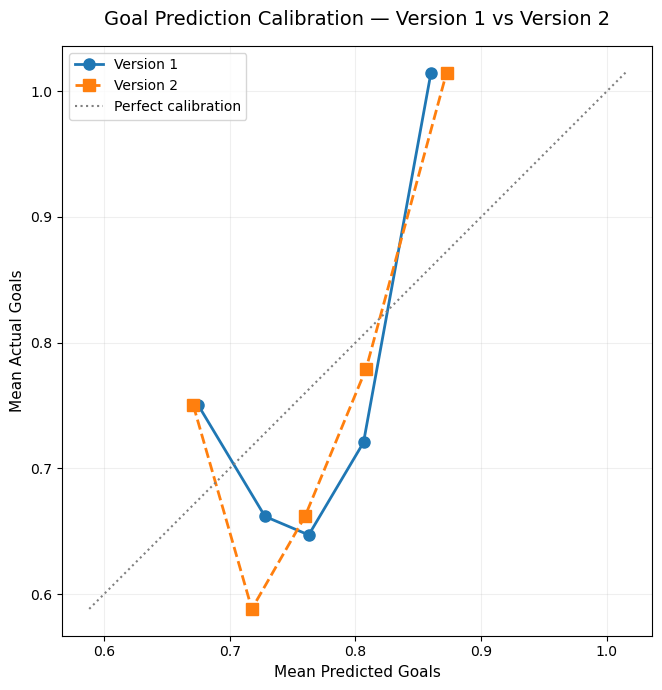

In [10]:
# Step 8: Visualize Version 1 and Version 2 calibration

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 7))

model_styles = {
    "Version 1": {
        "marker": "o",
        "linestyle": "-",
    },
    "Version 2": {
        "marker": "s",
        "linestyle": "--",
    },
}

for model_name, group in calibration_df.groupby("model"):

    group = group.sort_values("mean_prediction")

    ax.plot(
        group["mean_prediction"],
        group["mean_actual"],
        label=model_name,
        markersize=8,
        linewidth=2,
        **model_styles[model_name],
    )

# Perfect mean calibration reference
reference_min = min(
    calibration_df["mean_prediction"].min(),
    calibration_df["mean_actual"].min(),
)

reference_max = max(
    calibration_df["mean_prediction"].max(),
    calibration_df["mean_actual"].max(),
)

ax.plot(
    [reference_min, reference_max],
    [reference_min, reference_max],
    color="gray",
    linestyle=":",
    linewidth=1.5,
    label="Perfect calibration",
)

ax.set_title(
    "Goal Prediction Calibration — Version 1 vs Version 2",
    fontsize=14,
    pad=15,
)

ax.set_xlabel("Mean Predicted Goals", fontsize=11)
ax.set_ylabel("Mean Actual Goals", fontsize=11)

ax.grid(alpha=0.2)
ax.legend()
ax.set_aspect("equal", adjustable="box")

plt.tight_layout()
plt.show()

In [12]:
# Step 9: Examine observed goal-count distributions across folds

# Count appearances by the number of goals scored
goal_distribution = pd.crosstab(
    validation_df["fold"],
    validation_df["y_true"],
)

# Ensure all observed goal counts are represented
goal_distribution = goal_distribution.reindex(
    columns=range(
        int(validation_df["y_true"].max()) + 1
    ),
    fill_value=0,
)

# Convert counts into percentages within each fold
goal_distribution_pct = (
    goal_distribution.div(
        goal_distribution.sum(axis=1),
        axis=0,
    ) * 100
)

print("OBSERVED GOAL DISTRIBUTION — COUNTS")
print("=" * 85)

print(goal_distribution.to_string())

print("\nOBSERVED GOAL DISTRIBUTION — PERCENTAGES")
print("=" * 85)

print(
    goal_distribution_pct.round(2).to_string()
)

# Summarize scoreless and multiple-goal appearances
scoring_profile = (
    validation_df
    .assign(
        scoreless=lambda df: df["y_true"] == 0,
        scored=lambda df: df["y_true"] >= 1,
        multiple_goals=lambda df: df["y_true"] >= 2,
    )
    .groupby("fold", sort=True)
    .agg(
        appearances=("match_id", "count"),
        goals_per_appearance=("y_true", "mean"),
        scoreless_rate=("scoreless", "mean"),
        scoring_rate=("scored", "mean"),
        multiple_goal_rate=("multiple_goals", "mean"),
    )
)

# Express rates as percentages
rate_columns = [
    "scoreless_rate",
    "scoring_rate",
    "multiple_goal_rate",
]

scoring_profile[rate_columns] *= 100

print("\nSCORING PROFILE BY VALIDATION FOLD")
print("=" * 100)

print(scoring_profile.round(3).to_string())

# Verify that the distribution covers every validation appearance
assert goal_distribution.to_numpy().sum() == 340

assert (
    goal_distribution.sum(axis=1)
    == scoring_profile["appearances"]
).all()

print("\nGoal distribution checks: PASSED")

OBSERVED GOAL DISTRIBUTION — COUNTS
y_true   0   1   2  3  4
fold                    
Fold 1  69  60  23  5  1
Fold 2  47  17   5  3  0
Fold 3  23  22  11  2  1
Fold 4  20  22   6  3  0

OBSERVED GOAL DISTRIBUTION — PERCENTAGES
y_true      0      1      2     3     4
fold                                   
Fold 1  43.67  37.97  14.56  3.16  0.63
Fold 2  65.28  23.61   6.94  4.17  0.00
Fold 3  38.98  37.29  18.64  3.39  1.69
Fold 4  39.22  43.14  11.76  5.88  0.00

SCORING PROFILE BY VALIDATION FOLD
        appearances  goals_per_appearance  scoreless_rate  scoring_rate  multiple_goal_rate
fold                                                                                       
Fold 1          158                 0.791          43.671        56.329              18.354
Fold 2           72                 0.500          65.278        34.722              11.111
Fold 3           59                 0.915          38.983        61.017              23.729
Fold 4           51                 

In [14]:
# Step 10: Inspect available numerical features for shift analysis

# Load the engineered dataset without modifying it
engineered_df = pd.read_csv(DATA_PATH)

# Restrict the analysis to the 340 saved validation appearances
feature_validation_df = validation_df[
    ["match_id", "fold", "date"]
].merge(
    engineered_df.drop(columns=["date"], errors="ignore"),
    on="match_id",
    how="left",
    validate="one_to_one",
)

assert len(feature_validation_df) == 340
assert feature_validation_df["match_id"].is_unique

# Identify numerical columns available for analysis
numeric_columns = feature_validation_df.select_dtypes(
    include=[np.number]
).columns.tolist()

# Exclude targets, saved predictions, and identifiers
excluded_columns = {
    "target_goals",
    "y_true",
    "v1_prediction",
    "v2_prediction",
}

numeric_features = [
    column
    for column in numeric_columns
    if column not in excluded_columns
    and not column.lower().startswith("target_")
]

print("FEATURE DISTRIBUTION ANALYSIS — DATA INSPECTION")
print("=" * 80)

print(f"Validation appearances: {len(feature_validation_df)}")
print(f"Total columns: {feature_validation_df.shape[1]}")
print(f"Numerical feature candidates: {len(numeric_features)}")

print("\nAVAILABLE NUMERICAL FEATURES")
print("=" * 80)

for index, feature in enumerate(numeric_features, start=1):
    print(f"{index:>2}. {feature}")

print("\nMISSING VALUES — TOP 10 NUMERICAL FEATURES")
print("=" * 80)

missing_counts = (
    feature_validation_df[numeric_features]
    .isna()
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(missing_counts.to_string())

print("\nFeature inspection completed.")

FEATURE DISTRIBUTION ANALYSIS — DATA INSPECTION
Validation appearances: 340
Total columns: 101
Numerical feature candidates: 86

AVAILABLE NUMERICAL FEATURES
 1. is_national_team
 2. competition_importance
 3. age_years
 4. age_days
 5. career_appearances_pre
 6. career_goals_pre
 7. career_assists_pre
 8. goals_to_1000_pre
 9. career_goals_per_game_pre
10. days_rest
11. matches_last_7d
12. matches_last_14d
13. matches_last_30d
14. goals_last_3
15. goals_last_5
16. goals_last_10
17. goals_last_20
18. assists_last_5
19. assists_last_10
20. goals_per_game_last_5
21. goals_per_game_last_10
22. goals_per_game_last_20
23. scoring_rate_last_5
24. scoring_rate_last_10
25. multi_goal_rate_last_10
26. goals_ewma_pre
27. assists_ewma_pre
28. consecutive_scoring_games_pre
29. goalless_streak_games_pre
30. days_since_last_goal
31. season_appearances_pre
32. season_goals_pre
33. season_assists_pre
34. season_goals_per_game_pre
35. team_appearances_with_ronaldo_pre
36. team_goals_by_ronaldo_pre
37. 

In [16]:
# Step 11: Compare selected pre-match features across validation folds

selected_features = [
    "goals_per_game_last_5",
    "goals_per_game_last_10",
    "goals_ewma_pre",
    "career_goals_per_game_pre",
    "season_goals_per_game_pre",
    "matchup_elo_diff_pre",
    "days_rest",
    "matches_last_14d",
]

# Confirm all selected features exist
missing_features = [
    feature
    for feature in selected_features
    if feature not in feature_validation_df.columns
]

assert not missing_features, (
    f"Missing features: {missing_features}"
)

# Check whether the selected features contain missing values
missing_values = (
    feature_validation_df[selected_features]
    .isna()
    .sum()
)

print("SELECTED FEATURE MISSING VALUES")
print("=" * 75)
print(missing_values.to_string())

# Calculate descriptive statistics for each validation fold
feature_shift_rows = []

for feature in selected_features:

    for fold_name, group in feature_validation_df.groupby(
        "fold",
        sort=True,
    ):

        values = group[feature].dropna()

        feature_shift_rows.append({
            "feature": feature,
            "fold": fold_name,
            "matches": len(values),
            "mean": values.mean(),
            "median": values.median(),
            "std": values.std(),
            "min": values.min(),
            "max": values.max(),
        })

feature_shift_df = pd.DataFrame(feature_shift_rows)

# Display fold-level means for easier comparison
feature_means = feature_shift_df.pivot(
    index="feature",
    columns="fold",
    values="mean",
)

print("\nFEATURE MEANS ACROSS VALIDATION FOLDS")
print("=" * 100)

print(feature_means.round(4).to_string())

# Calculate the range of fold-level means
feature_means["mean_range"] = (
    feature_means[["Fold 1", "Fold 2", "Fold 3", "Fold 4"]].max(axis=1)
    - feature_means[["Fold 1", "Fold 2", "Fold 3", "Fold 4"]].min(axis=1)
)

print("\nRANGE OF FOLD-LEVEL FEATURE MEANS")
print("=" * 75)

print(
    feature_means["mean_range"]
    .sort_values(ascending=False)
    .round(4)
    .to_string()
)

print("\nFeature distribution summary completed.")

SELECTED FEATURE MISSING VALUES
goals_per_game_last_5        0
goals_per_game_last_10       0
goals_ewma_pre               0
career_goals_per_game_pre    0
season_goals_per_game_pre    0
matchup_elo_diff_pre         0
days_rest                    0
matches_last_14d             0

FEATURE MEANS ACROSS VALIDATION FOLDS
fold                         Fold 1    Fold 2    Fold 3    Fold 4
feature                                                          
career_goals_per_game_pre    0.7229    0.7266    0.7198    0.7276
days_rest                    6.9177    7.3750    6.5254    6.7059
goals_ewma_pre               0.7836    0.5376    0.8570    0.8307
goals_per_game_last_10       0.7816    0.5597    0.8339    0.8216
goals_per_game_last_5        0.7823    0.5417    0.8542    0.8275
matches_last_14d             2.2975    2.0556    2.2712    2.1176
matchup_elo_diff_pre       157.9342  146.0889  101.0990  186.2527
season_goals_per_game_pre    0.8083    0.5556    0.7619    0.9102

RANGE OF FOLD-LEVEL 

In [18]:
# Step 12: Examine prediction sensitivity to recent scoring form

FORM_FEATURE = "goals_per_game_last_5"

sensitivity_df = validation_df[
    [
        "match_id",
        "fold",
        "y_true",
        "v1_prediction",
        "v2_prediction",
    ]
].merge(
    feature_validation_df[
        ["match_id", FORM_FEATURE]
    ],
    on="match_id",
    how="left",
    validate="one_to_one",
)

assert len(sensitivity_df) == 340
assert sensitivity_df[FORM_FEATURE].notna().all()

sensitivity_rows = []

# Examine the relationship across all appearances and within folds
analysis_groups = [
    ("Overall", sensitivity_df),
    *list(sensitivity_df.groupby("fold", sort=True)),
]

for group_name, group in analysis_groups:

    for model_name, prediction_col in [
        ("Version 1", "v1_prediction"),
        ("Version 2", "v2_prediction"),
    ]:

        # Correlation is undefined if either variable is constant
        pearson_corr = group[
            [FORM_FEATURE, prediction_col]
        ].corr(method="pearson").iloc[0, 1]

        spearman_corr = group[
            [FORM_FEATURE, prediction_col]
        ].corr(method="spearman").iloc[0, 1]

        sensitivity_rows.append({
            "period": group_name,
            "model": model_name,
            "matches": len(group),
            "mean_recent_form": group[FORM_FEATURE].mean(),
            "mean_prediction": group[prediction_col].mean(),
            "pearson_correlation": pearson_corr,
            "spearman_correlation": spearman_corr,
        })

sensitivity_results_df = pd.DataFrame(sensitivity_rows)

print("PREDICTION SENSITIVITY TO RECENT SCORING FORM")
print("=" * 110)

print(
    sensitivity_results_df.round(6).to_string(index=False)
)

# Examine how predictions vary across recent-form groups
form_group_df = sensitivity_df.copy()

form_group_df["form_group"] = pd.qcut(
    form_group_df[FORM_FEATURE].rank(method="first"),
    q=5,
    labels=False,
) + 1

form_group_summary = (
    form_group_df
    .groupby("form_group")
    .agg(
        appearances=("match_id", "count"),
        mean_recent_form=(FORM_FEATURE, "mean"),
        actual_goals=("y_true", "mean"),
        v1_prediction=("v1_prediction", "mean"),
        v2_prediction=("v2_prediction", "mean"),
    )
    .reset_index()
)

print("\nPREDICTIONS ACROSS RECENT-FORM GROUPS")
print("=" * 110)

print(
    form_group_summary.round(6).to_string(index=False)
)

print("\nPrediction sensitivity analysis completed.")

PREDICTION SENSITIVITY TO RECENT SCORING FORM
 period     model  matches  mean_recent_form  mean_prediction  pearson_correlation  spearman_correlation
Overall Version 1      340          0.750588         0.766466             0.201064              0.195227
Overall Version 2      340          0.750588         0.765868             0.174807              0.160011
 Fold 1 Version 1      158          0.782278         0.793762             0.165043              0.108065
 Fold 1 Version 2      158          0.782278         0.800468             0.096697              0.055845
 Fold 2 Version 1       72          0.541667         0.738552             0.430209              0.404451
 Fold 2 Version 2       72          0.541667         0.723447             0.220606              0.164253
 Fold 3 Version 1       59          0.854237         0.690635             0.179256              0.115214
 Fold 3 Version 2       59          0.854237         0.689356             0.195636              0.131884
 Fold 4 V

In [20]:
# Step 13: Compare recent scoring form and model predictions
# against actual match outcomes

relationship_rows = []

predictor_columns = {
    "Recent form (last 5)": "goals_per_game_last_5",
    "Version 1 prediction": "v1_prediction",
    "Version 2 prediction": "v2_prediction",
}

analysis_groups = [
    ("Overall", sensitivity_df),
    *list(sensitivity_df.groupby("fold", sort=True)),
]

for period_name, group in analysis_groups:

    for predictor_name, predictor_col in predictor_columns.items():

        pearson_corr = group[
            [predictor_col, "y_true"]
        ].corr(method="pearson").iloc[0, 1]

        spearman_corr = group[
            [predictor_col, "y_true"]
        ].corr(method="spearman").iloc[0, 1]

        relationship_rows.append({
            "period": period_name,
            "predictor": predictor_name,
            "matches": len(group),
            "pearson_correlation": pearson_corr,
            "spearman_correlation": spearman_corr,
        })

outcome_relationship_df = pd.DataFrame(
    relationship_rows
)

print("ASSOCIATION WITH ACTUAL MATCH GOALS")
print("=" * 100)

print(
    outcome_relationship_df
    .round(6)
    .to_string(index=False)
)

# Summarize the overall relationships
overall_relationships = (
    outcome_relationship_df[
        outcome_relationship_df["period"] == "Overall"
    ]
    .copy()
)

print("\nOVERALL PREDICTIVE ASSOCIATIONS")
print("=" * 80)

print(
    overall_relationships[
        [
            "predictor",
            "pearson_correlation",
            "spearman_correlation",
        ]
    ].round(6).to_string(index=False)
)

print("\nOutcome relationship analysis completed.")

ASSOCIATION WITH ACTUAL MATCH GOALS
 period            predictor  matches  pearson_correlation  spearman_correlation
Overall Recent form (last 5)      340            -0.011949              0.005414
Overall Version 1 prediction      340             0.089845              0.105922
Overall Version 2 prediction      340             0.105535              0.112001
 Fold 1 Recent form (last 5)      158            -0.083184             -0.086321
 Fold 1 Version 1 prediction      158             0.104094              0.122922
 Fold 1 Version 2 prediction      158             0.114245              0.133166
 Fold 2 Recent form (last 5)       72             0.139499              0.176308
 Fold 2 Version 1 prediction       72             0.126860              0.082180
 Fold 2 Version 2 prediction       72             0.092201             -0.028883
 Fold 3 Recent form (last 5)       59            -0.244412             -0.244512
 Fold 3 Version 1 prediction       59             0.062834              0

In [22]:
# Step 14: Evaluate a chronological historical-average baseline

# Use the original engineered dataset for historical outcomes
historical_df = engineered_df[
    ["match_id", "date", "target_goals"]
].copy()

historical_df["date"] = pd.to_datetime(
    historical_df["date"]
)

historical_df = historical_df.sort_values(
    ["date", "match_id"]
).reset_index(drop=True)

baseline_rows = []
baseline_predictions = []

for fold_name, group in validation_df.groupby("fold", sort=True):

    fold_start = group["date"].min()

    # I use only observations before the validation period.
    historical_train = historical_df[
        historical_df["date"] < fold_start
    ]

    assert len(historical_train) > 0

    historical_mean = historical_train[
        "target_goals"
    ].mean()

    assert np.isfinite(historical_mean)
    assert historical_mean > 0

    y_true = group["y_true"].to_numpy()

    y_baseline = np.full(
        len(group),
        historical_mean,
    )

    baseline_rows.append({
        "fold": fold_name,
        "train_matches": len(historical_train),
        "validation_matches": len(group),
        "historical_mean": historical_mean,
        "actual_mean": y_true.mean(),
        "baseline_poisson_deviance": mean_poisson_deviance(
            y_true,
            y_baseline,
        ),
        "baseline_mae": mean_absolute_error(
            y_true,
            y_baseline,
        ),
    })

    baseline_predictions.append(
        pd.DataFrame({
            "match_id": group["match_id"].to_numpy(),
            "fold": fold_name,
            "baseline_prediction": y_baseline,
        })
    )

baseline_results_df = pd.DataFrame(baseline_rows)

baseline_oof_df = pd.concat(
    baseline_predictions,
    ignore_index=True,
)

assert len(baseline_oof_df) == 340
assert baseline_oof_df["match_id"].is_unique

print("CHRONOLOGICAL HISTORICAL-AVERAGE BASELINE")
print("=" * 110)

print(
    baseline_results_df.round(6).to_string(index=False)
)

# Compare fold-level Poisson deviance
baseline_comparison = baseline_results_df[
    ["fold", "baseline_poisson_deviance"]
].merge(
    deviance_comparison[
        ["Version 1", "Version 2"]
    ].reset_index(),
    on="fold",
    validate="one_to_one",
)

baseline_comparison["v2_vs_baseline"] = (
    baseline_comparison["Version 2"]
    - baseline_comparison["baseline_poisson_deviance"]
)

print("\nPOISSON DEVIANCE COMPARISON")
print("=" * 100)

print(
    baseline_comparison.round(6).to_string(index=False)
)

print("\nMACRO POISSON DEVIANCE")
print("=" * 75)

print(
    "Historical baseline:",
    round(
        baseline_results_df[
            "baseline_poisson_deviance"
        ].mean(),
        6,
    ),
)

print(
    "Version 1:",
    round(deviance_comparison["Version 1"].mean(), 6),
)

print(
    "Version 2:",
    round(deviance_comparison["Version 2"].mean(), 6),
)

print("\nChronological baseline evaluation completed.")

CHRONOLOGICAL HISTORICAL-AVERAGE BASELINE
  fold  train_matches  validation_matches  historical_mean  actual_mean  baseline_poisson_deviance  baseline_mae
Fold 1            915                 158         0.719126     0.791139                   1.060074      0.700111
Fold 2           1073                  72         0.729730     0.500000                   1.241734      0.722973
Fold 3           1145                  59         0.715284     0.915254                   1.141760      0.757649
Fold 4           1204                  51         0.725083     0.843137                   1.019909      0.686747

POISSON DEVIANCE COMPARISON
  fold  baseline_poisson_deviance  Version 1  Version 2  v2_vs_baseline
Fold 1                   1.060074   1.044600   1.042958       -0.017116
Fold 2                   1.241734   1.238840   1.232247       -0.009487
Fold 3                   1.141760   1.153896   1.155293        0.013533
Fold 4                   1.019909   0.988650   0.984179       -0.035730

MAC

In [24]:
# Step 15: Inspect the frozen temporal-fold contract

FOLDS_PATH = (
    PROJECT_ROOT
    / "artifacts"
    / "temporal_folds.json"
)

assert FOLDS_PATH.is_file(), (
    f"Temporal-fold contract not found: {FOLDS_PATH}"
)

with open(FOLDS_PATH, encoding="utf-8") as file:
    temporal_contract = json.load(file)

print("FROZEN TEMPORAL-FOLD CONTRACT")
print("=" * 85)

print("Top-level structure:")
print(type(temporal_contract).__name__)

if isinstance(temporal_contract, dict):
    print("\nTop-level keys:")
    print(list(temporal_contract.keys()))

elif isinstance(temporal_contract, list):
    print("\nNumber of entries:")
    print(len(temporal_contract))

print("\nFIRST CONTRACT ENTRY")
print("=" * 85)

# Inspect the structure without modifying the contract.
if isinstance(temporal_contract, list):

    first_entry = temporal_contract[0]

    if isinstance(first_entry, dict):
        print("Entry keys:", list(first_entry.keys()))

    print(
        json.dumps(
            first_entry,
            indent=2,
            default=str,
        )[:4000]
    )

elif isinstance(temporal_contract, dict):

    for key, value in temporal_contract.items():

        print(f"\nKey: {key}")
        print(f"Value type: {type(value).__name__}")

        if isinstance(value, list):
            print(f"Number of entries: {len(value)}")

            if value:
                print(
                    json.dumps(
                        value[0],
                        indent=2,
                        default=str,
                    )[:2500]
                )

        elif isinstance(value, dict):
            print("Nested keys:", list(value.keys()))

        else:
            print("Value:", str(value)[:500])

print("\nFrozen contract inspection completed.")

FROZEN TEMPORAL-FOLD CONTRACT
Top-level structure:
list

Number of entries:
4

FIRST CONTRACT ENTRY
Entry keys: ['name', 'train_start', 'train_end', 'validation_start', 'validation_end', 'train_matches', 'validation_matches']
{
  "name": "Fold 1",
  "train_start": "2002-08-14",
  "train_end": "2018-06-30",
  "validation_start": "2018-08-18",
  "validation_end": "2021-06-27",
  "train_matches": 915,
  "validation_matches": 158
}

Frozen contract inspection completed.


In [26]:
# Step 16: Verify the historical baseline against frozen fold boundaries

boundary_check_rows = []

for fold_spec in temporal_contract:

    fold_name = fold_spec["name"]

    train_start = pd.Timestamp(fold_spec["train_start"])
    train_end = pd.Timestamp(fold_spec["train_end"])

    validation_start = pd.Timestamp(
        fold_spec["validation_start"]
    )

    validation_end = pd.Timestamp(
        fold_spec["validation_end"]
    )

    # Reconstruct the training window specified in the contract.
    contract_train = historical_df[
        historical_df["date"].between(
            train_start,
            train_end,
            inclusive="both",
        )
    ]

    # Reconstruct the training window used by my baseline.
    baseline_train = historical_df[
        historical_df["date"] < validation_start
    ]

    # Compare actual match identifiers, not just row counts.
    contract_ids = set(contract_train["match_id"])
    baseline_ids = set(baseline_train["match_id"])

    training_sets_match = contract_ids == baseline_ids

    # Verify the validation dates against the frozen contract.
    fold_validation = validation_df[
        validation_df["fold"] == fold_name
    ]

    validation_dates_match = (
        fold_validation["date"].min() == validation_start
        and fold_validation["date"].max() == validation_end
    )

    boundary_check_rows.append({
        "fold": fold_name,
        "contract_train": len(contract_train),
        "baseline_train": len(baseline_train),
        "expected_train": fold_spec["train_matches"],
        "expected_validation": fold_spec["validation_matches"],
        "actual_validation": len(fold_validation),
        "training_sets_match": training_sets_match,
        "validation_dates_match": validation_dates_match,
        "extra_baseline_matches": len(
            baseline_ids - contract_ids
        ),
        "missing_baseline_matches": len(
            contract_ids - baseline_ids
        ),
    })

boundary_check_df = pd.DataFrame(boundary_check_rows)

print("BASELINE TRAINING BOUNDARY VERIFICATION")
print("=" * 120)

print(
    boundary_check_df.to_string(index=False)
)

# Check the contract's training and validation counts.
counts_match = (
    (
        boundary_check_df["contract_train"]
        == boundary_check_df["expected_train"]
    ).all()
    and (
        boundary_check_df["actual_validation"]
        == boundary_check_df["expected_validation"]
    ).all()
)

sets_match = boundary_check_df[
    "training_sets_match"
].all()

dates_match = boundary_check_df[
    "validation_dates_match"
].all()

print("\nVERIFICATION SUMMARY")
print("=" * 75)

print("Training counts match:", counts_match)
print("Training match sets identical:", sets_match)
print("Validation dates match:", dates_match)

if counts_match and sets_match and dates_match:
    print("\nBaseline training boundaries: VERIFIED")
else:
    print(
        "\nBaseline training boundaries require further review."
    )

BASELINE TRAINING BOUNDARY VERIFICATION
  fold  contract_train  baseline_train  expected_train  expected_validation  actual_validation  training_sets_match  validation_dates_match  extra_baseline_matches  missing_baseline_matches
Fold 1             915             915             915                  158                158                 True                    True                       0                         0
Fold 2            1073            1073            1073                   72                 72                 True                    True                       0                         0
Fold 3            1145            1145            1145                   59                 59                 True                    True                       0                         0
Fold 4            1204            1204            1204                   51                 51                 True                    True                       0                         0

VERIFICAT

In [28]:
# Step 17: Assess paired prediction improvements against both benchmarks

from scipy.special import xlogy

# I combine all three prediction sets using their match identifiers.
robustness_df = validation_df[
    [
        "match_id",
        "fold",
        "date",
        "y_true",
        "v1_prediction",
        "v2_prediction",
    ]
].merge(
    baseline_oof_df[
        ["match_id", "baseline_prediction"]
    ],
    on="match_id",
    how="left",
    validate="one_to_one",
)

assert len(robustness_df) == 340
assert robustness_df["baseline_prediction"].notna().all()

# I calculate per-appearance Poisson deviance contributions.
def poisson_deviance_contributions(y_true, y_pred):

    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)

    assert np.all(y_true >= 0)
    assert np.all(y_pred > 0)

    return 2 * (
        xlogy(y_true, y_true / y_pred)
        - y_true
        + y_pred
    )


prediction_columns = {
    "Baseline": "baseline_prediction",
    "Version 1": "v1_prediction",
    "Version 2": "v2_prediction",
}

for model_name, prediction_col in prediction_columns.items():

    robustness_df[f"{model_name}_deviance"] = (
        poisson_deviance_contributions(
            robustness_df["y_true"],
            robustness_df[prediction_col],
        )
    )

# Negative differences indicate that Version 2 performs better.
robustness_df["v2_minus_v1"] = (
    robustness_df["Version 2_deviance"]
    - robustness_df["Version 1_deviance"]
)

robustness_df["v2_minus_baseline"] = (
    robustness_df["Version 2_deviance"]
    - robustness_df["Baseline_deviance"]
)

comparison_rows = []

for comparison_name, difference_col in [
    ("V2 vs Version 1", "v2_minus_v1"),
    ("V2 vs Baseline", "v2_minus_baseline"),
]:

    for fold_name, group in [
        ("Overall", robustness_df),
        *list(robustness_df.groupby("fold", sort=True)),
    ]:

        differences = group[difference_col]

        comparison_rows.append({
            "comparison": comparison_name,
            "period": fold_name,
            "matches": len(group),
            "mean_deviance_change": differences.mean(),
            "median_deviance_change": differences.median(),
            "improved_matches": int((differences < 0).sum()),
            "worsened_matches": int((differences > 0).sum()),
            "improved_pct": 100 * (differences < 0).mean(),
        })

paired_robustness_df = pd.DataFrame(comparison_rows)

print("PAIRED ROBUSTNESS ASSESSMENT")
print("=" * 125)

print(
    paired_robustness_df
    .round(6)
    .to_string(index=False)
)

# Verify that paired mean deviance matches the pooled metric.
for model_name, prediction_col in prediction_columns.items():

    calculated = robustness_df[
        f"{model_name}_deviance"
    ].mean()

    expected = mean_poisson_deviance(
        robustness_df["y_true"],
        robustness_df[prediction_col],
    )

    assert np.isclose(calculated, expected)

print("\nPaired Poisson deviance checks: PASSED")
print("Negative deviance change indicates improvement.")

PAIRED ROBUSTNESS ASSESSMENT
     comparison  period  matches  mean_deviance_change  median_deviance_change  improved_matches  worsened_matches  improved_pct
V2 vs Version 1 Overall      340             -0.002587               -0.001684               192               148     56.470588
V2 vs Version 1  Fold 1      158             -0.001642               -0.002243                94                64     59.493671
V2 vs Version 1  Fold 2       72             -0.006593               -0.003001                43                29     59.722222
V2 vs Version 1  Fold 3       59              0.001398                0.000721                29                30     49.152542
V2 vs Version 1  Fold 4       51             -0.004471               -0.000078                26                25     50.980392
 V2 vs Baseline Overall      340             -0.012974               -0.012085               181               159     53.235294
 V2 vs Baseline  Fold 1      158             -0.017116              

In [30]:
# Step 18: Bootstrap uncertainty in Version 2 versus baseline

BOOTSTRAP_REPETITIONS = 5000
RANDOM_SEED = 42

rng = np.random.default_rng(RANDOM_SEED)

fold_differences = [
    group["v2_minus_baseline"].to_numpy()
    for _, group in robustness_df.groupby("fold", sort=True)
]

observed_macro_change = np.mean([
    differences.mean()
    for differences in fold_differences
])

bootstrap_macro_changes = np.empty(
    BOOTSTRAP_REPETITIONS,
    dtype=float,
)

# I resample paired deviance differences within each fold.
for iteration in range(BOOTSTRAP_REPETITIONS):

    sampled_fold_means = []

    for differences in fold_differences:

        sampled_indices = rng.integers(
            low=0,
            high=len(differences),
            size=len(differences),
        )

        sampled_fold_means.append(
            differences[sampled_indices].mean()
        )

    bootstrap_macro_changes[iteration] = np.mean(
        sampled_fold_means
    )

lower_bound, upper_bound = np.percentile(
    bootstrap_macro_changes,
    [2.5, 97.5],
)

fraction_favoring_v2 = np.mean(
    bootstrap_macro_changes < 0
)

print("VERSION 2 VS. HISTORICAL BASELINE — BOOTSTRAP")
print("=" * 80)

print(f"Bootstrap repetitions: {BOOTSTRAP_REPETITIONS:,}")

print(
    f"Observed macro deviance change: "
    f"{observed_macro_change:.6f}"
)

print(
    f"Bootstrap mean change: "
    f"{bootstrap_macro_changes.mean():.6f}"
)

print(
    f"Exploratory 95% interval: "
    f"({lower_bound:.6f}, {upper_bound:.6f})"
)

print(
    f"Fraction of resamples favoring V2: "
    f"{fraction_favoring_v2:.4f}"
)

print("\nINTERPRETATION")
print("-" * 80)

if upper_bound < 0:
    print(
        "The exploratory interval lies below zero, "
        "favoring Version 2."
    )
elif lower_bound > 0:
    print(
        "The exploratory interval lies above zero, "
        "favoring the historical baseline."
    )
else:
    print(
        "The exploratory interval includes zero; "
        "the direction of improvement remains uncertain."
    )

print(
    "\nNote: This bootstrap does not account fully for "
    "temporal dependence or model-selection uncertainty."
)

VERSION 2 VS. HISTORICAL BASELINE — BOOTSTRAP
Bootstrap repetitions: 5,000
Observed macro deviance change: -0.012200
Bootstrap mean change: -0.012005
Exploratory 95% interval: (-0.036410, 0.011130)
Fraction of resamples favoring V2: 0.8438

INTERPRETATION
--------------------------------------------------------------------------------
The exploratory interval includes zero; the direction of improvement remains uncertain.

Note: This bootstrap does not account fully for temporal dependence or model-selection uncertainty.


In [ ]:
# Step 19: Save the Version 2 model-validation report

from datetime import datetime, timezone

V2_REPORT_DIR.mkdir(parents=True, exist_ok=True)

validation_summary_path = (
    V2_REPORT_DIR / "model_validation_summary.json"
)

validation_report_path = (
    V2_REPORT_DIR / "model_validation_report.md"
)

baseline_macro = baseline_results_df[
    "baseline_poisson_deviance"
].mean()

v1_macro = deviance_comparison["Version 1"].mean()
v2_macro = deviance_comparison["Version 2"].mean()

validation_summary = {
    "experiment": "Version 2 Model Validation",
    "status": "experimental_not_promoted",
    "generated_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "validation": {
        "strategy": "expanding_window_chronological",
        "folds": 4,
        "appearances": len(validation_df),
        "final_test_used": False,
        "baseline_training_boundaries_verified": bool(
            counts_match and sets_match and dates_match
        ),
    },
    "macro_poisson_deviance": {
        "historical_baseline": float(baseline_macro),
        "version_1": float(v1_macro),
        "version_2": float(v2_macro),
    },
    "version_2_improvement_pct": {
        "vs_version_1": float(
            100 * (v1_macro - v2_macro) / v1_macro
        ),
        "vs_historical_baseline": float(
            100 * (baseline_macro - v2_macro)
            / baseline_macro
        ),
    },
    "paired_comparison": {
        "v2_vs_v1_improved_matches": 192,
        "v2_vs_baseline_improved_matches": 181,
    },
    "baseline_bootstrap": {
        "repetitions": BOOTSTRAP_REPETITIONS,
        "observed_macro_change": float(
            observed_macro_change
        ),
        "interval_95": [
            float(lower_bound),
            float(upper_bound),
        ],
        "fraction_favoring_v2": float(
            fraction_favoring_v2
        ),
    },
    "promotion_decision": {
        "promote_version_2": False,
        "reason": (
            "Observed improvements are modest, "
            "inconsistent across folds, and uncertain "
            "under exploratory bootstrap analysis."
        ),
    },
}

with open(
    validation_summary_path,
    "w",
    encoding="utf-8",
) as file:

    json.dump(
        validation_summary,
        file,
        indent=2,
    )


validation_report = f"""# Version 2 — Model Validation Report

## 1. Objective

I evaluated whether my experimental Version 2 goal-scoring
ensemble demonstrates sufficiently reliable improvements
over Version 1 to justify model promotion.

I preserved the frozen Version 1 implementation and
restricted this analysis to the Version 2 experiment workspace.

## 2. Validation Protocol

- Strategy: expanding-window chronological validation
- Validation folds: 4
- Out-of-fold appearances: {len(validation_df)}
- Historical final-test observations used: No
- Baseline training boundaries: Verified
- Primary metric: mean Poisson deviance

I evaluated Version 1, Version 2, and a historical-average
baseline using identical validation appearances.

## 3. Model Performance

| Model | Macro Poisson deviance |
|---|---:|
| Historical-average baseline | {baseline_macro:.6f} |
| Version 1 | {v1_macro:.6f} |
| Version 2 | {v2_macro:.6f} |

Version 2 reduced macro Poisson deviance by
{100 * (v1_macro - v2_macro) / v1_macro:.2f}%
relative to Version 1 and
{100 * (baseline_macro - v2_macro) / baseline_macro:.2f}%
relative to the historical-average baseline.

Both improvements are modest.

## 4. Temporal Generalization

Version 2 outperformed Version 1 in three of four
chronological folds.

It also outperformed the historical-average baseline
in three of four folds.

Fold 3 remained problematic: both ensembles performed
worse than the baseline and underestimated the observed
scoring rate.

I interpret this as evidence that predictive performance
is not consistent across historical periods.

## 5. Calibration and Scoring Distribution

The five-bin descriptive calibration analysis produced:

- Version 1 calibration error: 0.099481
- Version 2 calibration error: 0.095535

These results suggest a small descriptive improvement
in calibration, but they do not establish statistical
significance.

The observed scoring distribution varied substantially
between folds, particularly in the frequency of
scoreless appearances and multi-goal matches.

## 6. Recent Scoring Form

Recent goals per appearance over the previous five matches
showed little overall association with next-match goals:

- Pearson correlation: -0.011949
- Spearman correlation: 0.005414

I therefore found insufficient evidence to justify
increasing model sensitivity to recent scoring form
solely because predictions appeared conservative.

## 7. Paired Robustness

Version 2 improved:

- 192 of 340 appearances relative to Version 1
- 181 of 340 appearances relative to the historical baseline

The observed improvements were not uniform across folds.

## 8. Bootstrap Uncertainty

I used 5,000 fold-stratified paired bootstrap repetitions
to examine Version 2 against the historical baseline.

- Observed macro deviance change: {observed_macro_change:.6f}
- Exploratory 95% interval: ({lower_bound:.6f}, {upper_bound:.6f})
- Fraction of resamples favoring Version 2:
  {fraction_favoring_v2:.4f}

The interval includes zero, so the direction of
improvement remains uncertain.

The bootstrap resamples individual appearances within
folds and does not fully preserve temporal dependence.

Version 2 was also selected using these validation
folds, so this analysis is not independent confirmation
of its superiority.

## 9. Limitations

1. The validation dataset contains only 340 appearances.
2. Individual chronological folds are relatively small.
3. Goal outcomes exhibit substantial match-level variability.
4. Scoring distributions differ across historical periods.
5. Model selection and evaluation share validation data.
6. The bootstrap does not fully account for temporal dependence.
7. No independent forward evaluation has yet been completed.

## 10. Promotion Decision

**Decision: Do not promote Version 2.**

Although Version 2 achieves slightly better observed
Poisson deviance, the improvement is modest and uncertain.

I will retain Version 1 as the frozen production model
and preserve Version 2 as an experimental candidate.

Before considering promotion, I would require stronger
evidence from an independent forward evaluation using
a predefined comparison protocol.

I will not use the reserved historical final-test
observations for further hyperparameter tuning.

## 11. Conclusion

This experiment showed that increasing model complexity
does not automatically produce meaningful improvements
in goal-scoring forecasts.

My main finding is that Version 2 offers a small
observed advantage, but not enough evidence to justify
replacing Version 1.

The next priority is independent evaluation rather
than additional tuning against the existing folds.
"""

validation_report_path.write_text(
    validation_report,
    encoding="utf-8",
)

print("MODEL VALIDATION REPORT SAVED")
print("=" * 85)

print("JSON summary:", validation_summary_path)
print("Markdown report:", validation_report_path)

print("\nSUMMARY CHECK")
print("=" * 85)

print(
    json.dumps(
        {
            "status": validation_summary["status"],
            "folds": validation_summary["validation"]["folds"],
            "appearances": validation_summary["validation"]["appearances"],
            "baseline_verified": validation_summary[
                "validation"
            ]["baseline_training_boundaries_verified"],
            "promote_v2": validation_summary[
                "promotion_decision"
            ]["promote_version_2"],
        },
        indent=2,
    )
)

print("\nNotebook 02 report generation completed.")

In [34]:
# Step 20: Final integrity checks for Notebook 02

assert validation_summary_path.is_file()
assert validation_report_path.is_file()

with open(
    validation_summary_path,
    encoding="utf-8",
) as file:
    saved_summary = json.load(file)

saved_report = validation_report_path.read_text(
    encoding="utf-8"
)

# I verify that the saved metrics match my calculations.
saved_metrics = saved_summary["macro_poisson_deviance"]

assert np.isclose(
    saved_metrics["historical_baseline"],
    baseline_macro,
)

assert np.isclose(
    saved_metrics["version_1"],
    v1_macro,
)

assert np.isclose(
    saved_metrics["version_2"],
    v2_macro,
)

# I verify the evaluation boundaries.
assert saved_summary["validation"]["folds"] == 4
assert saved_summary["validation"]["appearances"] == 340

assert saved_summary["validation"][
    "baseline_training_boundaries_verified"
] is True

assert validation_df["date"].max() < FINAL_TEST_START

# I verify that the promotion decision remains unchanged.
assert saved_summary["status"] == "experimental_not_promoted"

assert saved_summary["promotion_decision"][
    "promote_version_2"
] is False

# I confirm that my outputs are stored in the V2 workspace.
v2_root = (
    PROJECT_ROOT / "experiments" / "v2"
).resolve()

for output_path in [
    validation_summary_path,
    validation_report_path,
]:
    assert output_path.resolve().is_relative_to(v2_root)

# I verify that the report contains its main conclusions.
required_sections = [
    "## 2. Validation Protocol",
    "## 3. Model Performance",
    "## 4. Temporal Generalization",
    "## 8. Bootstrap Uncertainty",
    "## 9. Limitations",
    "## 10. Promotion Decision",
]

for section in required_sections:
    assert section in saved_report, (
        f"Missing report section: {section}"
    )

print("NOTEBOOK 02 — FINAL INTEGRITY CHECK")
print("=" * 80)

print("JSON summary: VALID")
print("Markdown report: VALID")
print("Saved performance metrics: VERIFIED")
print("Chronological boundaries: VERIFIED")
print("Baseline training windows: VERIFIED")
print("Final-test observations excluded: VERIFIED")
print("Output location: V2 workspace")
print("Model promotion: NOT APPROVED")

print("\nFINAL PERFORMANCE")
print("=" * 80)

print(f"Historical baseline: {baseline_macro:.6f}")
print(f"Version 1:          {v1_macro:.6f}")
print(f"Version 2:          {v2_macro:.6f}")

print("\nAll Notebook 02 integrity checks passed.")

NOTEBOOK 02 — FINAL INTEGRITY CHECK
JSON summary: VALID
Markdown report: VALID
Saved performance metrics: VERIFIED
Chronological boundaries: VERIFIED
Baseline training windows: VERIFIED
Final-test observations excluded: VERIFIED
Output location: V2 workspace
Model promotion: NOT APPROVED

FINAL PERFORMANCE
Historical baseline: 1.115870
Version 1:          1.106496
Version 2:          1.103669

All Notebook 02 integrity checks passed.
